# Análise de nomeações e exonerações

## Importação

In [27]:
import re
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ARQ_NOMEADOS = "nomes_nomeados.csv"
ARQ_EXONERADOS = "nomes_exonerados.csv"

df_nom = pd.read_csv(ARQ_NOMEADOS)
df_exo = pd.read_csv(ARQ_EXONERADOS)

print(f"Nomeações: {len(df_nom):,} atos")
print(f"Exonerações: {len(df_exo):,} atos")
print("\nColunas:")
print("Nomeados:", df_nom.columns.tolist())
print("Exonerados:", df_exo.columns.tolist())


Nomeações: 2,597 atos
Exonerações: 2,276 atos

Colunas:
Nomeados: ['id', 'dataPubli', 'Nomeados']
Exonerados: ['id', 'dataPubli', 'Exonerados']


## Limpeza

### Diagnóstico

In [28]:
def diagnostico(df, coluna):
    s = df[coluna].fillna("").astype(str)
    print(f"--- {coluna} ---")
    print("Linhas:", len(df))
    print("IDs únicos:", df["id"].nunique())
    print("Duplicatas de linha:", df.duplicated().sum())
    print("Nulos:", df[coluna].isna().sum())
    print("Com EMPREGADO:", s.str.contains(r"\bEMPREGADO\b", case=False, regex=True).sum())
    print("Com MENCIONA:", s.str.contains(r"MENCIONA", case=False, regex=True).sum())
    print("Com PM/RG como tokens:", s.str.contains(r"\b(?:PM|RG)\b", case=False, regex=True).sum())
    print("Com CARGO :", s.str.contains(r"\bCARGO\b", case=False, regex=True).sum())
    print("Com NOMEIA (em exonerações):", s.str.contains(r"\bNOMEIA\b", case=False, regex=True).sum())
    print("Intervalo:", pd.to_datetime(df["dataPubli"], errors="coerce").min().date(),
          "até", pd.to_datetime(df["dataPubli"], errors="coerce").max().date())
    print()

diagnostico(df_nom, "Nomeados")
diagnostico(df_exo, "Exonerados")


--- Nomeados ---
Linhas: 2597
IDs únicos: 2597
Duplicatas de linha: 0
Nulos: 0
Com EMPREGADO: 39
Com MENCIONA: 51
Com PM/RG como tokens: 71
Com CARGO : 31
Com NOMEIA (em exonerações): 0
Intervalo: 2017-08-30 até 2026-07-01

--- Exonerados ---
Linhas: 2276
IDs únicos: 2276
Duplicatas de linha: 0
Nulos: 0
Com EMPREGADO: 35
Com MENCIONA: 36
Com PM/RG como tokens: 20
Com CARGO : 1
Com NOMEIA (em exonerações): 21
Intervalo: 2017-08-30 até 2026-07-01



### Limpeza dos casos mapeados

In [45]:
TERMOS_DESCARTE = [
    r"\bMENCIONA\b",
    r"\bCARGO\b",
    r"\bEMPREGADO\b",
    r"\bNOMEIA\b",
    r"\bRG\b",
    r"\bPM\b",
    r"\bEMPRESA\b",
    r"\bFUNCIONAL\b"
    ]

PADRAO_DESCARTE = re.compile(
    "|".join(TERMOS_DESCARTE),
    flags=re.IGNORECASE
)


def limpar_segmento_nome(seg):
    """Limpa um segmento individual.

    Se o segmento contiver qualquer termo que indique texto
    administrativo, descarta SOMENTE esse segmento.
    """
    
    if pd.isna(seg):
        return None

    s = str(seg).strip()

    if not s:
        return None

    # Se este segmento contiver um termo administrativo,
    # ele é descartado, mas os demais segmentos da mesma
    # célula continuam sendo processados.
    if PADRAO_DESCARTE.search(s):
        return None

    return s or None


def limpar_coluna_nomes(valor):

    if pd.isna(valor):
        return []

    # Cada elemento separado por vírgula é tratado
    # independentemente.
    partes = [p.strip() for p in str(valor).split(",")]

    nomes_limpos = []

    for parte in partes:

        nome = limpar_segmento_nome(parte)

        # Somente o segmento problemático é eliminado.
        if nome:
            nomes_limpos.append(nome)

    return nomes_limpos

# Lista de nomes por ato
df_nom["nomes_limpos"] = df_nom["Nomeados"].apply(limpar_coluna_nomes)
df_exo["nomes_limpos"] = df_exo["Exonerados"].apply(limpar_coluna_nomes)

display(df_nom.loc[df_nom["id"]==2620968])
display(df_exo.loc[df_exo["id"]==2640759])


,id,dataPubli,Nomeados,nomes_limpos
153,2620968,2025-01-22,"EMPREGADO NA FORMA QUE MENCIONA, PAULO JOSE KN...",[PAULO JOSE KNOPP DE AQUINO]


,id,dataPubli,Exonerados,nomes_limpos
609,2640759,2025-04-15,"PEDRO LUCAS SANTOS BARRETO, TEN CEL PM RG",[PEDRO LUCAS SANTOS BARRETO]


### Quantificar o efeito da limpeza

In [46]:
def contar_nomes(series_list):
    return sum(len(x) for x in series_list)

print("Total de nomes/ocorrências antes da limpeza:")
print("  Nomeações:", df_nom["Nomeados"].fillna("").apply(lambda x: len([p for p in str(x).split(",") if p.strip()])).sum())
print("  Exonerações:", df_exo["Exonerados"].fillna("").apply(lambda x: len([p for p in str(x).split(",") if p.strip()])).sum())

print("\nTotal de nomes/ocorrências após a limpeza:")
print("  Nomeações:", contar_nomes(df_nom["nomes_limpos"]))
print("  Exonerações:", contar_nomes(df_exo["nomes_limpos"]))

# Mostra resíduos que ainda contêm tokens suspeitos para auditoria.
for nome_df, coluna in [(df_nom, "nomes_limpos"), (df_exo, "nomes_limpos")]:
    residuos = nome_df.explode(coluna)[coluna].dropna()
    residuos = residuos[residuos.str.contains(r"\b(?:CEL|PM|RG|EMPREGADO|NA\s+FORMA)\b", case=False, regex=True)]
    print(f"\nResíduos suspeitos em {coluna}: {len(residuos)}")
    display(residuos.head(30))


Total de nomes/ocorrências antes da limpeza:
  Nomeações: 13542
  Exonerações: 11551

Total de nomes/ocorrências após a limpeza:
  Nomeações: 13384
  Exonerações: 11441

Resíduos suspeitos em nomes_limpos: 0


Series([], Name: nomes_limpos, dtype: str)


Resíduos suspeitos em nomes_limpos: 0


Series([], Name: nomes_limpos, dtype: str)

### Normalizar 1 nome por linha

In [47]:
def normalizar_nome(nome):
    if pd.isna(nome):
        return None
    s = str(nome).upper().strip()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"[^A-Z0-9\s']", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s or None

def criar_base_pessoas(df, coluna_lista, tipo):
    base = df[["id", "dataPubli", coluna_lista]].explode(coluna_lista).copy()
    base = base.rename(columns={coluna_lista: "nome_original"})
    base["nome_original"] = base["nome_original"].astype("string").str.strip()
    base = base[base["nome_original"].notna() & (base["nome_original"] != "")]
    base["nome_normalizado"] = base["nome_original"].apply(normalizar_nome)
    base["dataPubli"] = pd.to_datetime(base["dataPubli"], errors="coerce")
    base["tipo"] = tipo
    return base.reset_index(drop=True)

nomeados = criar_base_pessoas(df_nom, "nomes_limpos", "Nomeação")
exonerados = criar_base_pessoas(df_exo, "nomes_limpos", "Exoneração")

print(f"Ocorrências individuais de nomes — nomeações: {len(nomeados):,}")
print(f"Ocorrências individuais de nomes — exonerações: {len(exonerados):,}")
print(f"Nomes distintos normalizados — nomeações: {nomeados['nome_normalizado'].nunique():,}")
print(f"Nomes distintos normalizados — exonerações: {exonerados['nome_normalizado'].nunique():,}")


Ocorrências individuais de nomes — nomeações: 13,384
Ocorrências individuais de nomes — exonerações: 11,441
Nomes distintos normalizados — nomeações: 11,736
Nomes distintos normalizados — exonerações: 10,240


## Estatísticas

### Gerais

In [48]:
for base, titulo in [(nomeados, "Nomeações"), (exonerados, "Exonerações")]:
    por_ato = base.groupby("id")["nome_normalizado"].nunique()
    print(f"### {titulo}")
    print(f"Atos com nomes: {por_ato.size:,}")
    print(f"Nomes distintos: {base['nome_normalizado'].nunique():,}")
    print(f"Média de nomes por ato: {por_ato.mean():.2f}")
    print(f"Mediana de nomes por ato: {por_ato.median():.0f}")
    print(f"Máximo de nomes em um ato: {por_ato.max():,}")
    print()

    resumo = base["dataPubli"].dt.year.value_counts().sort_index().rename("atos_com_ocorrencias")
    display(resumo.to_frame())


### Nomeações
Atos com nomes: 2,488
Nomes distintos: 11,736
Média de nomes por ato: 5.37
Mediana de nomes por ato: 1
Máximo de nomes em um ato: 102



,atos_com_ocorrencias
dataPubli,
2017,36
2025,11307
2026,2041


### Exonerações
Atos com nomes: 2,252
Nomes distintos: 10,240
Média de nomes por ato: 5.08
Mediana de nomes por ato: 1
Máximo de nomes em um ato: 300



,atos_com_ocorrencias
dataPubli,
2017,16
2025,8556
2026,2869


### Nomes Recorrentes

In [51]:
# Frequência dos nomes mais recorrentes
freq_nom = (nomeados.groupby("nome_normalizado")
            .agg(ocorrencias_nomeacao=("nome_normalizado", "size"),
                 atos_nomeacao=("id", "nunique"),
                 primeira_nomeacao=("dataPubli", "min"),
                 ultima_nomeacao=("dataPubli", "max"))
            .sort_values(["ocorrencias_nomeacao", "atos_nomeacao"], ascending=False))

freq_exo = (exonerados.groupby("nome_normalizado")
            .agg(ocorrencias_exoneracao=("nome_normalizado", "size"),
                 atos_exoneracao=("id", "nunique"),
                 primeira_exoneracao=("dataPubli", "min"),
                 ultima_exoneracao=("dataPubli", "max"))
            .sort_values(["ocorrencias_exoneracao", "atos_exoneracao"], ascending=False))


display(freq_nom.head(15))

display(freq_exo.head(15))


,ocorrencias_nomeacao,atos_nomeacao,primeira_nomeacao,ultima_nomeacao
nome_normalizado,,,,
CARLOS LEONARDO RAMOS POVOA,5,5,2025-08-14,2025-12-11
FABIANO SALDANHA GOMES DE OLIVEIRA,5,5,2025-04-01,2026-04-16
FELIPE FERREIRA DE LIMA,5,5,2025-03-12,2026-06-02
GUSTAVO REIS FERREIRA,5,5,2025-01-16,2025-11-12
JAIR DE SIQUEIRA BITTENCOURT JUNIOR,5,5,2025-02-26,2025-11-19
JOAO CLAUDIO WAGNER SILVA,5,5,2025-04-04,2026-01-26
MARCELA VASCONCELOS VENTURA,5,5,2025-02-12,2026-01-13
MATHEUS MENDONCA PINHEIRO,5,5,2025-03-17,2025-10-14
MAURICIO QUIRINO DE SOUZA,5,5,2025-01-23,2025-11-13


,ocorrencias_exoneracao,atos_exoneracao,primeira_exoneracao,ultima_exoneracao
nome_normalizado,,,,
ALEX SANDER DA SILVA SURIANO,5,5,2025-01-29,2026-06-23
FELIPE FERREIRA DE LIMA,5,5,2025-03-12,2026-05-25
GUSTAVO REIS FERREIRA,5,5,2025-01-14,2025-11-04
JOAO CLAUDIO WAGNER SILVA,5,5,2025-04-24,2026-01-26
MAURICIO QUIRINO DE SOUZA,5,5,2025-02-12,2025-12-16
ROBSON JOSE STORANI,5,5,2025-01-16,2025-11-11
GABRIEL PAIVA HASS,5,3,2025-02-24,2025-03-07
ALEXANDER EVARISTO DA SILVA,4,4,2025-03-18,2026-06-23
ALEXANDRE FLORES GUERRA,4,4,2025-03-26,2026-06-23


## Visualização

### Temporal

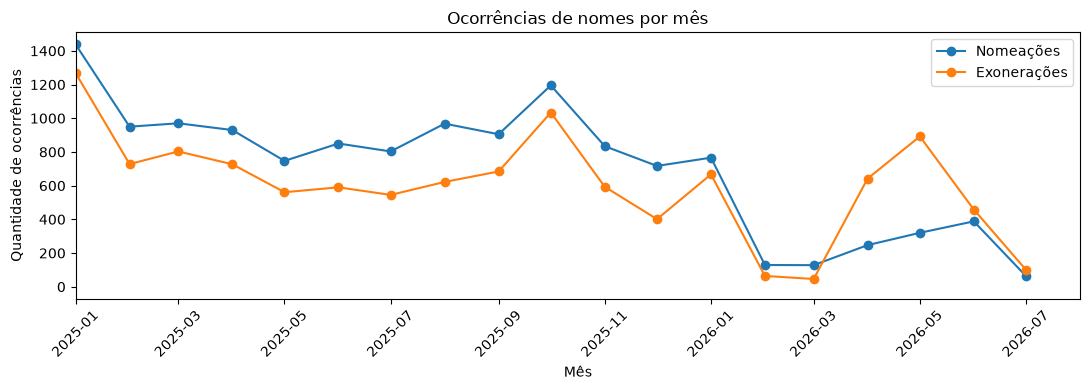

In [58]:
def serie_mensal(base):
    return (base.set_index("dataPubli")
            .resample("MS")
            .size()
            .rename("ocorrencias")
            .reset_index())

mensal_nom = serie_mensal(nomeados)
mensal_exo = serie_mensal(exonerados)

inicio = pd.Timestamp("2025-01-01")
fim = max(mensal_nom["dataPubli"].max(), mensal_exo["dataPubli"].max()) + pd.DateOffset(months=1)

plt.figure(figsize=(11, 4))
plt.plot(mensal_nom["dataPubli"], mensal_nom["ocorrencias"], marker="o", label="Nomeações")
plt.plot(mensal_exo["dataPubli"], mensal_exo["ocorrencias"], marker="o", label="Exonerações")
plt.xlim(inicio, fim)
plt.title("Ocorrências de nomes por mês")
plt.xlabel("Mês")
plt.ylabel("Quantidade de ocorrências")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


### Nomes em comum

In [60]:
set_nom = set(nomeados["nome_normalizado"].dropna())
set_exo = set(exonerados["nome_normalizado"].dropna())

comuns = sorted(set_nom & set_exo)
so_nomeados = sorted(set_nom - set_exo)
so_exonerados = sorted(set_exo - set_nom)

print(f"Nomes distintos em comum: {len(comuns):,}")
print(f"Exclusivos de nomeações: {len(so_nomeados):,}")
print(f"Exclusivos de exonerações: {len(so_exonerados):,}")

comparacao = (freq_nom.join(freq_exo, how="outer")
              .fillna({"ocorrencias_nomeacao": 0, "atos_nomeacao": 0,
                       "ocorrencias_exoneracao": 0, "atos_exoneracao": 0})
              .reset_index())

comparacao["aparece_nas_duas"] = (
    (comparacao["ocorrencias_nomeacao"] > 0) &
    (comparacao["ocorrencias_exoneracao"] > 0)
)

print("\nPessoas que aparecem nas duas bases:")
comuns_df = comparacao[comparacao["aparece_nas_duas"]].copy()
comuns_df["total_ocorrencias"] = (
    comuns_df["ocorrencias_nomeacao"] + comuns_df["ocorrencias_exoneracao"]
)
display(comuns_df.sort_values("total_ocorrencias", ascending=False).head(10))


Nomes distintos em comum: 4,602
Exclusivos de nomeações: 7,134
Exclusivos de exonerações: 5,638

Pessoas que aparecem nas duas bases:


,nome_normalizado,ocorrencias_nomeacao,atos_nomeacao,primeira_nomeacao,ultima_nomeacao,ocorrencias_exoneracao,atos_exoneracao,primeira_exoneracao,ultima_exoneracao,aparece_nas_duas,total_ocorrencias
12131,MAURICIO QUIRINO DE SOUZA,5.0,5.0,2025-01-23,2025-11-13,5.0,5.0,2025-02-12,2025-12-16,True,10.0
6873,GUSTAVO REIS FERREIRA,5.0,5.0,2025-01-16,2025-11-12,5.0,5.0,2025-01-14,2025-11-04,True,10.0
14667,ROBSON JOSE STORANI,5.0,5.0,2025-01-16,2025-11-11,5.0,5.0,2025-01-16,2025-11-11,True,10.0
5598,FELIPE FERREIRA DE LIMA,5.0,5.0,2025-03-12,2026-06-02,5.0,5.0,2025-03-12,2026-05-25,True,10.0
7894,JOAO CLAUDIO WAGNER SILVA,5.0,5.0,2025-04-04,2026-01-26,5.0,5.0,2025-04-24,2026-01-26,True,10.0
421,ALEX SANDER DA SILVA SURIANO,4.0,4.0,2025-01-29,2026-01-26,5.0,5.0,2025-01-29,2026-06-23,True,9.0
2960,CARLOS LEONARDO RAMOS POVOA,5.0,5.0,2025-08-14,2025-12-11,4.0,4.0,2025-09-12,2025-12-11,True,9.0
12069,MATHEUS MENDONCA PINHEIRO,5.0,5.0,2025-03-17,2025-10-14,4.0,4.0,2025-04-07,2025-10-14,True,9.0
10808,MARCELA VASCONCELOS VENTURA,5.0,5.0,2025-02-12,2026-01-13,4.0,4.0,2025-03-06,2026-01-13,True,9.0
7522,JAIR DE SIQUEIRA BITTENCOURT JUNIOR,5.0,5.0,2025-02-26,2025-11-19,4.0,4.0,2025-03-11,2025-12-11,True,9.0
